# CIFAR-10: CNN versus FCNN

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Compare dense and convolutional models on ten image classes.

**Approach:** TensorFlow/Keras architecture comparison.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Mini Project  : Part 1 Project 3 (CIFAR-10 Deep Classification) FCNN </span>
    </span>
    </center>
<br>


## (CIFAR-10 Deep Classification)
### GUERBOUZ MOHAMMED ALAA EDDINE

In [12]:
# Import necessary libraries
from keras.datasets import cifar10
from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten
from keras.utils import to_categorical
from tensorflow.keras import datasets, layers, models
import cv2
import tensorflow as tf
import matplotlib.pyplot as plt

#### **Explanation:**
- We import TensorFlow and Keras for building and training the deep learning models.
- Matplotlib is used for visualizing the images.
- NumPy is used for numerical operations on the dataset. np

In [13]:
# Load the CIFAR-10 dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Define class names for CIFAR-10
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

#### **Explanation:**
- The CIFAR-10 dataset is loaded using TensorFlow's `keras.datasets.cifar10`.
- The dataset is split into training and testing sets:
  - `X_train` and `y_train` are used for training the model.
  - `X_test` and `y_test` are used for evaluating the model.
- `class_names` is a list of the 10 categories in the dataset.

Training images shape: (50000, 32, 32, 3)
Training labels shape: (50000, 1)
Test images shape: (10000, 32, 32, 3)
Test labels shape: (10000, 1)


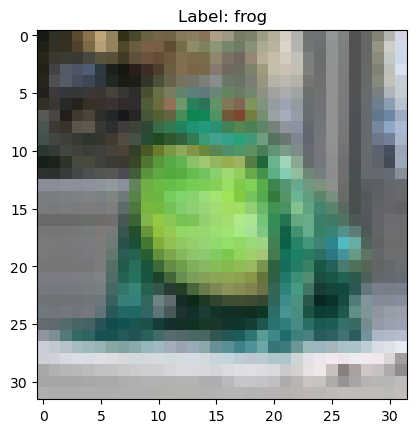

In [14]:
# Check the shape of the dataset
print("Training images shape:", X_train.shape)  # (50000, 32, 32, 3)
print("Training labels shape:", y_train.shape)  # (50000, 1)
print("Test images shape:", X_test.shape)       # (10000, 32, 32, 3)
print("Test labels shape:", y_test.shape)       # (10000, 1)

# Display the first image in the training set
plt.figure()
plt.imshow(X_train[19])
plt.title(f"Label: {class_names[y_train[19][0]]}")
plt.show()

#### **Explanation:**
- We check the shape of the dataset to confirm that there are 50,000 training images and 10,000 test images, each of size 32x32 pixels with 3 color channels (RGB).
- We visualize the first image in the training set using `matplotlib`. The title of the plot shows the corresponding label (e.g., "airplane").

In [15]:
# Normalize the pixel values to the range [0, 1]
X_train = X_train / 255.0
X_test = X_test / 255.0

# Convert labels to one-hot encoding (optional for FCNN)
y_train = tf.keras.utils.to_categorical(y_train, 10)
y_test = tf.keras.utils.to_categorical(y_test, 10)


#### **Explanation:**
- The pixel values are normalized to the range `[0, 1]` by dividing by 255. This helps the model converge faster during training.
- The labels are converted to one-hot encoded vectors, which are required for certain loss functions like `categorical_crossentropy`. If you use `sparse_categorical_crossentropy`, this step is optional.l.

In [17]:
# Define the FCNN model
model = models.Sequential([
    layers.Flatten(input_shape=(32, 32, 3)),  # Flatten the input image
    layers.Dense(128, activation='relu'),     # Fully connected layer with 128 neurons
    layers.Dense(64, activation='relu'),      # Fully connected layer with 64 neurons
    layers.Dense(10, activation='softmax')    # Output layer with softmax activation
])


# Compile the CNN model
model.compile(optimizer='adam',
                   loss='categorical_crossentropy',
                   metrics=['accuracy'])

# Print the model summary
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_1 (Flatten)         (None, 3072)              0         
                                                                 
 dense_3 (Dense)             (None, 128)               393344    
                                                                 
 dense_4 (Dense)             (None, 64)                8256      
                                                                 
 dense_5 (Dense)             (None, 10)                650       
                                                                 
Total params: 402250 (1.53 MB)
Trainable params: 402250 (1.53 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


#### **Explanation:**
- We build a **Fully Connected Neural Network (FCNN)** using Keras' `Sequential` API.
- The model consists of:
  - A **flatten layer** to convert the 2D input image into a 1D vector.
  - Two **fully connected (dense) layers** with ReLU activation.
  - An **output layer** with 10 neurons (one for each class) and softmax activation to output class probabilities.
- The model is compiled using the Adam optimizer, categorical cross-entropy loss, and accuracy as the evaluation metric. metric.

In [19]:
fcnn_history = model.fit(X_train, y_train, epochs=10, validation_data=(X_test, y_test))


Epoch 1/10
1563/1563 [==============================] - 9s 5ms/step - loss: 1.8914 - accuracy: 0.3170 - val_loss: 1.7309 - val_accuracy: 0.3767
Epoch 2/10
1563/1563 [==============================] - 7s 4ms/step - loss: 1.7070 - accuracy: 0.3921 - val_loss: 1.6312 - val_accuracy: 0.4164
Epoch 3/10
1563/1563 [==============================] - 7s 4ms/step - loss: 1.6374 - accuracy: 0.4148 - val_loss: 1.6462 - val_accuracy: 0.4087
Epoch 4/10
1563/1563 [==============================] - 6s 4ms/step - loss: 1.5857 - accuracy: 0.4325 - val_loss: 1.5571 - val_accuracy: 0.4379
Epoch 5/10
1563/1563 [==============================] - 7s 4ms/step - loss: 1.5583 - accuracy: 0.4427 - val_loss: 1.5437 - val_accuracy: 0.4516
Epoch 6/10
1563/1563 [==============================] - 7s 4ms/step - loss: 1.5300 - accuracy: 0.4518 - val_loss: 1.5557 - val_accuracy: 0.4428
Epoch 7/10
1563/1563 [==============================] - 7s 4ms/step - loss: 1.5041 - accuracy: 0.4625 - val_loss: 1.5663 - val_accuracy:

#### **Explanation:**
- model are trained for 10 epochs using the training data.
- The `validation_data` parameter allows the models to evaluate their performance on the test set after each epoch.
- The training history is stored in  `fcnn_history`, which can be used to plot the training and validation accuracy/loss.och.

In [20]:
# Evaluate the CNN model
fcnn_test_loss, cnn_test_acc = model.evaluate(X_test, y_test)
print(f"CNN Test Accuracy: {cnn_test_acc:.4f}")

test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_acc:.4f}")
print('\nLoss on the TEST Set: {:,.3f}'.format(test_loss))
print('Accuracy on the TEST Set: {:.3%}'.format(test_acc))

313/313 [==============================] - 0s 852us/step - loss: 1.5105 - accuracy: 0.4615
CNN Test Accuracy: 0.4615
313/313 [==============================] - 0s 846us/step - loss: 1.5105 - accuracy: 0.4615
Test Accuracy: 0.4615

Loss on the TEST Set: 1.510
Accuracy on the TEST Set: 46.150%


#### **Explanation:**
- The models' performance is evaluated on the test set using the `evaluate()` function.
- The test accuracy is printed, which indicates how well the models generalize to unseen data.ss.a.

In [23]:
import numpy as np
# Make predictions using the FCNN model
fcnn_predictions = model.predict(X_test)

# Display the predicted class for the first test image
fcnn_predicted_class = np.argmax(fcnn_predictions[0])
print(f"FCNN Predicted Class: {class_names[fcnn_predicted_class]}")
print(f"Actual Class: {class_names[np.argmax(y_test[0])]}")

313/313 [==============================] - 0s 776us/step
FCNN Predicted Class: cat
Actual Class: cat


#### **Explanation:**
- The models make predictions on the test set using the `predict()` function.
- The predicted class for the first test image is displayed, along with the actual class.

### Loss and Validation Plots

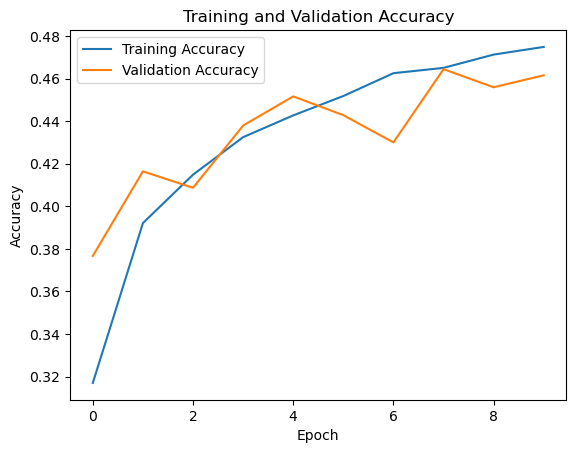

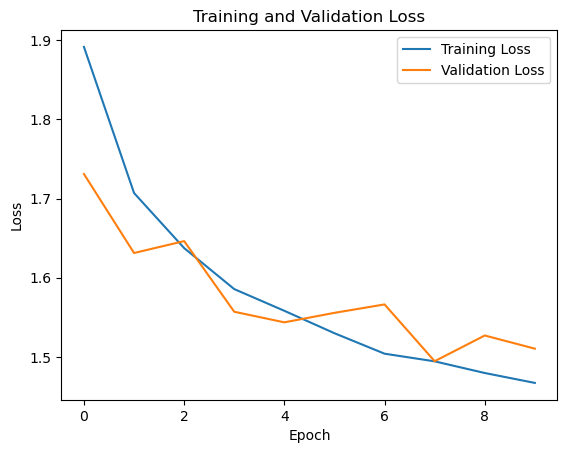

In [26]:
# Plot training and validation accuracy
plt.plot(fcnn_history.history['accuracy'], label='Training Accuracy')
plt.plot(fcnn_history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

# Plot training and validation loss
plt.plot(fcnn_history.history['loss'], label='Training Loss')
plt.plot(fcnn_history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

#### **Explanation:**
- The training and validation accuracy are plotted over the epochs to visualize the model's learning progress.
- The training and validation loss are also plotted to check for overfitting or underfitting.

### Test our model with an image from dataset 

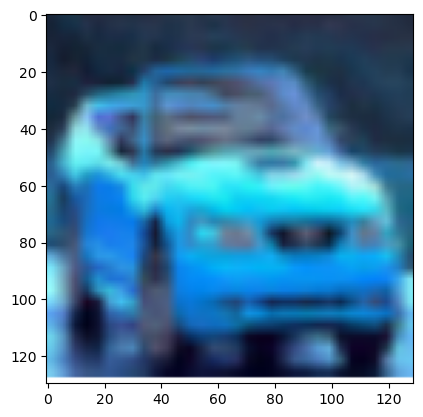

In [27]:
import cv2  
img = cv2.imread('testimg.png')
plt.imshow(img)


In [30]:
from keras.preprocessing.image import img_to_array, load_img
img = cv2.resize(img, (32, 32))  # Assuming the model expects input images of size 32x32

# Convert the image to array and normalize pixel values
img_array = img_to_array(img)
img_array = img_array / 255.0  # Normalize pixel values to [0, 1]

# Expand the dimensions to create a batch with a single sample
img_array = np.expand_dims(img_array, axis=0)

predictions= model.predict(img_array)


# Interpret the results
predicted_class = np.argmax(predictions)
confidence = np.max(predictions)

# Print the predicted class and confidence
print("Predicted class:", predicted_class)
print(f" {class_names[predicted_class]}")
# Display the predicted class for the first test image

print("Confidence:", confidence)


1/1 [==============================] - 0s 20ms/step
Predicted class: 1
 automobile
Confidence: 0.9603439


In [31]:
print(predictions)

[[7.3823789e-03 9.6034390e-01 2.0911382e-03 3.8609287e-06 3.4661411e-05
  5.2703808e-07 2.9231446e-06 1.1634038e-05 1.0947762e-02 1.9181132e-02]]


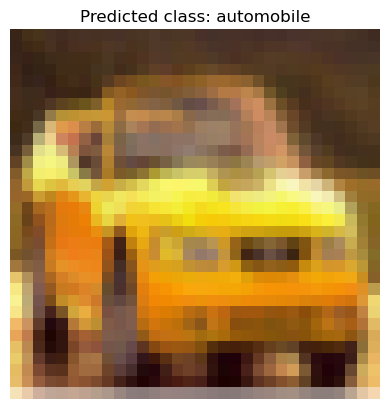

In [33]:
predicted_class = class_names[np.argmax(predictions)]

# Display the image with the predicted class label
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Predicted class: " + predicted_class)
plt.axis('off')
plt.show()